In [2]:
import piplite
await piplite.install(['seaborn', 'statsmodels'])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from pyodide.http import open_url

# URL-ден деректі жүктеу
boston_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
boston_df = pd.read_csv(open_url(boston_url))

boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


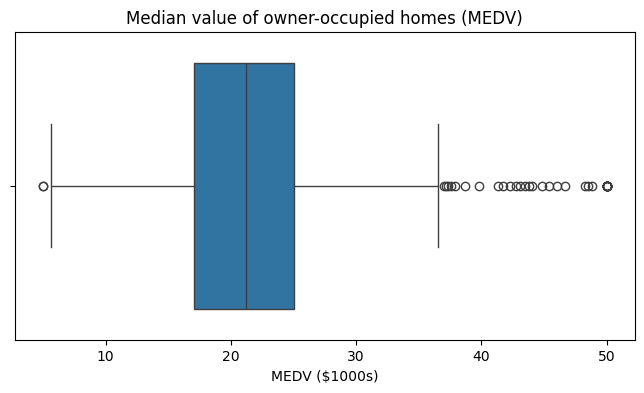

In [3]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=boston_df['MEDV'])
plt.title('Median value of owner-occupied homes (MEDV)')
plt.xlabel('MEDV ($1000s)')
plt.show()

**Explanation:** 
The boxplot shows the distribution of the median value of owner-occupied homes (MEDV). The median home value is approximately $21,000 - $22,000. There are multiple outliers on the higher side, with several observations capped at $50,000.

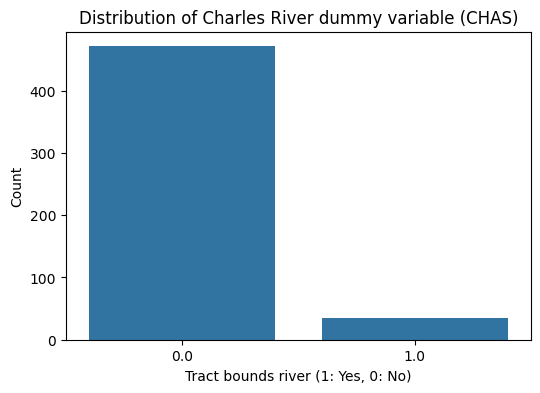

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(x='CHAS', data=boston_df)
plt.title('Distribution of Charles River dummy variable (CHAS)')
plt.xlabel('Tract bounds river (1: Yes, 0: No)')
plt.ylabel('Count')
plt.show()

**Explanation:** 
The bar plot shows that the vast majority of tracts do not bound the Charles River (category 0), while only a small number of properties track alongside the river (category 1).

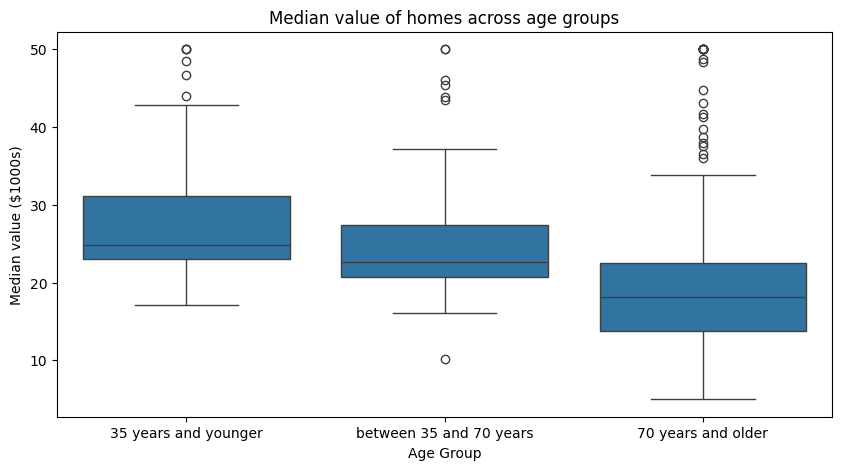

In [5]:
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

plt.figure(figsize=(10, 5))
sns.boxplot(x='age_group', y='MEDV', data=boston_df, order=['35 years and younger', 'between 35 and 70 years', '70 years and older'])
plt.title('Median value of homes across age groups')
plt.xlabel('Age Group')
plt.ylabel('Median value ($1000s)')
plt.show()

**Explanation:** 
The boxplot demonstrates that newer homes (35 years and younger) have the highest median values, whereas older homes (70 years and older) show the lowest median home prices.

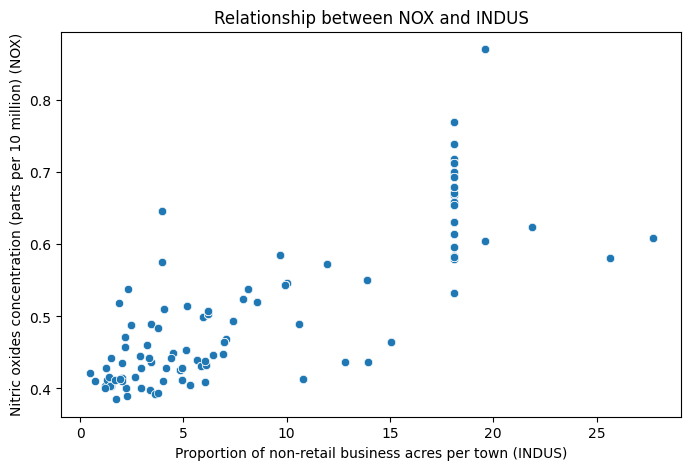

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
plt.title('Relationship between NOX and INDUS')
plt.xlabel('Proportion of non-retail business acres per town (INDUS)')
plt.ylabel('Nitric oxides concentration (parts per 10 million) (NOX)')
plt.show()

**Explanation:** 
The scatter plot indicates a strong positive linear relationship between the proportion of non-retail business acres (INDUS) and nitric oxides concentration (NOX). As industrial land use increases, NOX levels tend to rise.

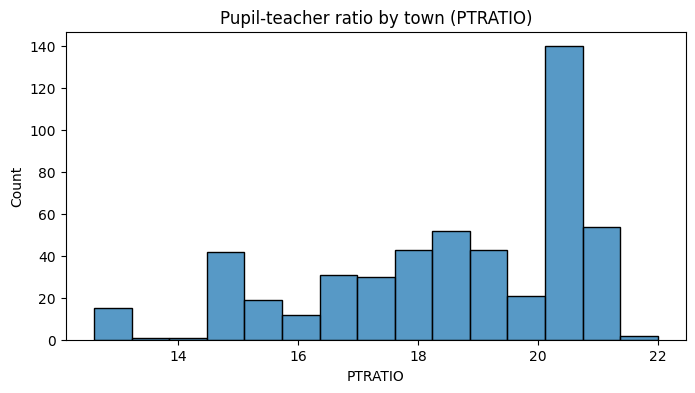

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(boston_df['PTRATIO'], bins=15, kde=False)
plt.title('Pupil-teacher ratio by town (PTRATIO)')
plt.xlabel('PTRATIO')
plt.ylabel('Count')
plt.show()

**Explanation:** 
The histogram illustrates the distribution of pupil-teacher ratios across towns. The distribution is negatively skewed, with the highest concentration appearing around 20–21 pupils per teacher.

### Task 1: Is there a significant difference in median value of houses bounded by the Charles river or not?

**Hypothesis:**
* $H_0: \mu_1 = \mu_2$ (There is no difference in median value between houses bounded by the Charles river and those that are not)
* $H_1: \mu_1 \neq \mu_2$ (There is a significant difference in median value between houses bounded by the Charles river and those that are not)

Significance level: $\alpha = 0.05$

In [11]:
# Levene's test for equality of variance
levene_stat, p_levene = stats.levene(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                                     boston_df[boston_df['CHAS'] == 1]['MEDV'])
print(f"Levene test p-value: {p_levene:.4f}")

# Independent samples t-test
t_stat, p_val = stats.ttest_ind(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                                boston_df[boston_df['CHAS'] == 1]['MEDV'],
                                equal_var=(p_levene > 0.05))
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val:.4e}")

Levene test p-value: 0.0326
T-statistic: -3.1133, p-value: 3.5672e-03


**Conclusion:** 
Since the p-value is less than the significance level of 0.05, we reject the null hypothesis ($H_0$). There is statistically significant evidence that the median value of houses bounded by the Charles River differs from those not bounded by the river (properties bounded by the river have higher values).

### Task 2: Is there a difference in Median values of houses (MEDV) for each proportion of owner occupied units built prior to 1940 (AGE)?

**Hypothesis:**
* $H_0: \mu_1 = \mu_2 = \mu_3$ (The mean MEDV is equal across all age groups)
* $H_1:$ At least one mean MEDV differs from the other age groups

Significance level: $\alpha = 0.05$

In [8]:
group_1 = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
group_2 = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
group_3 = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']

f_statistic, p_value_anova = stats.f_oneway(group_1, group_2, group_3)
print(f"F-statistic: {f_statistic:.4f}, p-value: {p_value_anova:.4e}")

F-statistic: 36.4076, p-value: 1.7105e-15


**Conclusion:** 
Since the p-value is less than 0.05, we reject the null hypothesis ($H_0$). There is statistically significant evidence that the median value of houses differs across the different age groups.

### Task 3: Can we conclude that there is an association between Nitric oxide concentrations and proportion of non-retail business acres per town?

**Hypothesis:**
* $H_0: \rho = 0$ (There is no linear relationship between NOX and INDUS)
* $H_1: \rho \neq 0$ (There is a significant linear relationship between NOX and INDUS)

Significance level: $\alpha = 0.05$

In [9]:
corr_coeff, p_value_corr = stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])
print(f"Pearson Correlation Coefficient: {corr_coeff:.4f}")
print(f"p-value: {p_value_corr:.4e}")

Pearson Correlation Coefficient: 0.7637
p-value: 7.9134e-98


**Conclusion:** 
Since the p-value is less than 0.05, we reject the null hypothesis ($H_0$). There is a statistically significant, strong positive correlation ($r \approx 0.76$) between nitric oxide concentrations (NOX) and the proportion of non-retail business acres per town (INDUS).

### Task 4: What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner occupied homes?

**Hypothesis:**
* $H_0: \beta_1 = 0$ (There is no linear impact of weighted distance to employment centres (DIS) on home values (MEDV))
* $H_1: \beta_1 \neq 0$ (There is a significant linear impact of weighted distance to employment centres (DIS) on home values (MEDV))

Significance level: $\alpha = 0.05$

In [10]:
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        00:50:04   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

**Conclusion:** 
Since the p-value for the DIS variable is less than 0.05 (p < 0.001), we reject the null hypothesis ($H_0$). The coefficient is positive (approx. 1.0916), indicating that each additional weighted unit of distance to the five Boston employment centres is associated with an increase in the median home value of approximately $1,092.